# 1.1 Exploración de modelos para P1

P1: ¿cuántos viajes se iniciarán en una estación en la siguiente hora? Aquí se prueban baselines y candidatos sobre validación. Prueba no se usa en este notebook.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

from mibici_equipo39 import config as C
from mibici_equipo39.features import CALENDAR_FEATURES, FEATURE_COLUMNS, eligible_stations, load_tables

metadata, X, y = load_tables()
keep = metadata["station_id"].isin(eligible_stations(metadata, y))
metadata, X, y = metadata[keep].reset_index(drop=True), X[keep].reset_index(drop=True), y[keep].reset_index(drop=True)
train = metadata["split"].eq("train").to_numpy()
val = metadata["split"].eq("validation").to_numpy()
print(metadata["station_id"].nunique(), "estaciones con 100 o más salidas en train")
print(train.sum(), "filas train,", val.sum(), "filas validación")

468 estaciones con 100 o más salidas en train
2830464 filas train, 584064 filas validación


## Variable objetivo

In [2]:
pd.Series({
    "media": y[train].mean(),
    "proporcion_en_cero": y[train].eq(0).mean(),
    "varianza / media": y[train].var() / y[train].mean(),
    "p99": y[train].quantile(0.99),
    "maximo": y[train].max(),
}).round(3)

media                   1.094
proporcion_en_cero      0.621
varianza / media        5.030
p99                    10.000
maximo                149.000
dtype: float64

> **Métricas.** Es un conteo con muchos ceros y algunas horas muy altas (varianza cinco veces la media). MAPE no sirve porque divide entre cero. La métrica principal es **MAE**, en viajes por estación y hora, que el operador entiende directo. **RMSE** se reporta al lado porque castiga más los errores grandes, que son las horas pico donde faltan bicicletas.

## Baselines

In [3]:
frame = metadata.assign(y=y, hour_of_day=X["hour_of_day"], day_of_week=X["day_of_week"])
global_mean = frame.loc[train, "y"].mean()
preds = {"media_global": np.full(val.sum(), global_mean)}
for name, keys in [("media_estacion_hora", ["station_id", "hour_of_day"]),
                   ("media_estacion_dia_hora", ["station_id", "day_of_week", "hour_of_day"])]:
    means = frame[train].groupby(keys, observed=True)["y"].mean().rename("p")
    preds[name] = frame[val].join(means, on=keys)["p"].fillna(global_mean).to_numpy()

y_val = y[val].to_numpy()
def score(p):
    return {"val_mae": mean_absolute_error(y_val, p), "val_rmse": root_mean_squared_error(y_val, p)}
pd.DataFrame({k: score(p) for k, p in preds.items()}).T.round(4)

,val_mae,val_rmse
media_global,1.3833,2.3505
media_estacion_hora,0.7610,1.5757
media_estacion_dia_hora,0.7119,1.4495


> **Baseline elegido: media por estación, día y hora.** Es lo que haría alguien con una tabla dinámica del historial y ya baja el MAE a la mitad de la media global. Es la vara que el modelo tiene que superar.

## Candidatos

Mismo algoritmo, HistGradientBoostingRegressor, para comparar variables y pérdida. Se escoge por su soporte de no linealidades e interacciones (hora con día) y porque entrena en segundos con casi 3 millones de filas.

In [4]:
configs = {
    "hgb_calendario_poisson": (CALENDAR_FEATURES, "poisson"),
    "hgb_rezagos_poisson": (FEATURE_COLUMNS, "poisson"),
    "hgb_rezagos_cuadratico": (FEATURE_COLUMNS, "squared_error"),
    "hgb_rezagos_absoluto": (FEATURE_COLUMNS, "absolute_error"),
}
for name, (cols, loss) in configs.items():
    model = HistGradientBoostingRegressor(**{**C.P1_HGB_PARAMS, "loss": loss})
    model.fit(X.loc[train, cols], y[train])
    preds[name] = np.clip(model.predict(X.loc[val, cols]), 0, None)

peak = y_val >= 10
summary = pd.DataFrame({
    k: {**score(p), "mae_horas_10_o_mas": mean_absolute_error(y_val[peak], p[peak]), "prediccion_maxima": p.max(), "prediccion_media": p.mean()}
    for k, p in preds.items()
}).T.round(4)
summary

,val_mae,val_rmse,mae_horas_10_o_mas,prediccion_maxima,prediccion_media
media_global,1.3833,2.3505,13.3907,1.0942,1.0942
media_estacion_hora,0.7610,1.5757,6.4408,35.0278,1.0942
media_estacion_dia_hora,0.7119,1.4495,5.4012,54.6286,1.1055
hgb_calendario_poisson,1.1945,2.2150,12.4621,3.8780,1.1295
hgb_rezagos_poisson,0.6729,1.4781,5.1430,451.8163,1.1041
hgb_rezagos_cuadratico,0.6730,1.2820,4.8279,98.2360,1.1053
hgb_rezagos_absoluto,1.0928,2.5921,14.4849,0.0000,0.0000


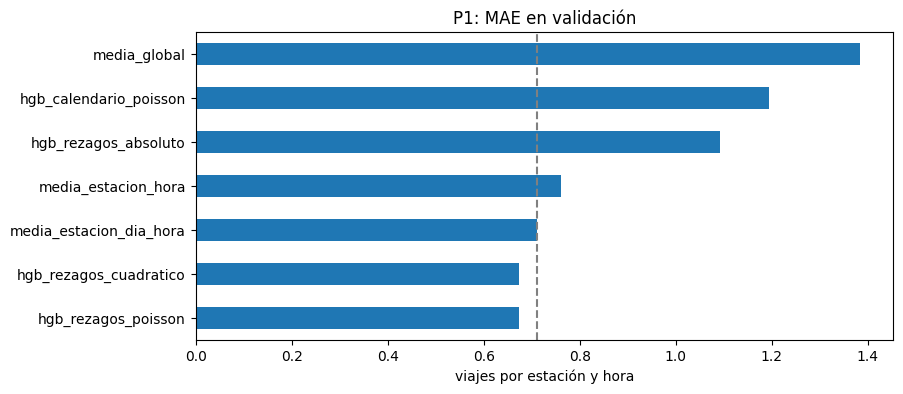

In [5]:
fig, ax = plt.subplots(figsize=(9, 4))
summary["val_mae"].sort_values().plot(kind="barh", ax=ax, title="P1: MAE en validación")
ax.axvline(summary.loc["media_estacion_dia_hora", "val_mae"], color="grey", linestyle="--")
ax.set_xlabel("viajes por estación y hora")
plt.savefig(C.FIGURES / "p1_exploracion_modelos.png", dpi=120, bbox_inches="tight")

> **Variables: calendario y rezagos.** Con solo calendario el modelo queda peor que el baseline porque no sabe de qué estación se trata. Al agregar los rezagos baja de la vara del baseline: la actividad de la última hora y de la misma hora de la semana pasada le dice el nivel de cada estación.
>
> **Pérdida: error cuadrático.** Poisson es la opción natural para conteos, pero su enlace logarítmico se dispara en algunas horas (predice cientos de viajes) y empeora el RMSE. El error absoluto predice la mediana, que es cero casi siempre, y no sirve. El error cuadrático empata el mejor MAE, tiene el menor RMSE y el menor error en las horas con 10 o más viajes.

## Decisión

| | Elección |
|---|---|
| Baseline | Media por estación, día y hora de train |
| Candidato | HistGradientBoostingRegressor, error cuadrático, 200 iteraciones, semilla 39 |
| Variables | Calendario de Stefania (con versiones cíclicas) y rezagos de 1, 2, 24 y 168 horas |
| Regla | Se queda el candidato si baja `val_mae`; prueba se evalúa una sola vez en MLflow |

Siguiente paso: `2.1-dm-p1-refactorizacion`, donde esto se convierte en clases.